# EDA dirigido y justificación de selección de variables — MIMIC-IV UCI 12 h

**Problema:** regresión de `los_restante_dias` a partir de información disponible durante las primeras 12 horas de estancia en UCI.

Este notebook parte del dataset analítico ya integrado. Su objetivo no es volver a integrar MIMIC-IV, sino construir y documentar una selección de variables más parsimoniosa y potencialmente más generalizable.

## Criterios de selección

1. **Evitar fuga de información:** `los` no puede utilizarse como predictor porque contiene la duración total de la estancia.
2. **Separar identificadores de predictores:** `subject_id` y `stay_id` se conservan para trazabilidad y para realizar posteriormente la partición por paciente, pero no entrarán al modelo.
3. **Generalización:** se priorizan variables demográficas, signos vitales y pruebas de laboratorio de carácter general. Las variables administrativas dependientes de la organización/codificación del hospital se excluyen del conjunto mínimo.
4. **Disponibilidad:** se cuantifica el porcentaje de datos faltantes de cada variable.
5. **Redundancia:** se examina la correlación de Spearman entre predictores; pares con |ρ| ≥ 0.80 se marcan para revisión.
6. **Parsimonia clínica:** para signos vitales se evita conservar simultáneamente mínimo, media y máximo cuando representan información altamente redundante.
7. **Laboratorios:** se prioriza un panel básico y se eliminan variables hematológicas o de coagulación redundantes/especializadas del conjunto mínimo.

> Importante: esta es una selección previa al modelado. La imputación, codificación, escalado y cualquier selección basada en desempeño predictivo deben ajustarse únicamente con el conjunto de entrenamiento.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import sys
from pathlib import Path

def encontrar_raiz_proyecto():
    actual = Path.cwd().resolve()
    for candidato in [actual, *actual.parents]:
        if (candidato / "src" / "config.py").exists():
            return candidato
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. "
        "Ejecuta este notebook dentro del repositorio estancia-hospitalaria-uci."
    )

PROJECT_ROOT = encontrar_raiz_proyecto()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import INTERIM_DIR, RESULTS_DIR

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

RUTA = INTERIM_DIR / "mimic_uci_12h_dataset_analitico.csv.gz"

df = pd.read_csv(RUTA)

print("Archivo:", RUTA)
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
display(df.head())


Archivo: C:\Users\grise\Downloads\estancia-hospitalaria-uci\data\interim\mimic_uci_12h_dataset_analitico.csv.gz
Dimensiones: 90,467 filas × 54 columnas


,subject_id,hadm_id,stay_id,los,los_restante_dias,edad_ingreso,gender,first_careunit,admission_type,admission_location,fc_min,fr_min,pad_min,pam_min,pas_min,spo2_min,temperatura_min,fc_mean,fr_mean,pad_mean,pam_mean,pas_mean,spo2_mean,temperatura_mean,fc_max,fr_max,pad_max,pam_max,pas_max,spo2_max,temperatura_max,lab_50868_anion_gap,lab_50882_bicarbonate,lab_50893_calcium_total,lab_50902_chloride,lab_50912_creatinine,lab_50931_glucose,lab_50960_magnesium,lab_50970_phosphate,lab_50971_potassium,lab_50983_sodium,lab_51006_urea_nitrogen,lab_51221_hematocrit,lab_51222_hemoglobin,lab_51237_inr_pt,lab_51248_mch,lab_51249_mchc,lab_51250_mcv,lab_51265_platelet_count,lab_51274_pt,lab_51275_ptt,lab_51277_rdw,lab_51279_red_blood_cells,lab_51301_white_blood_cells
0,10000690,25860671,37081114,3.893252,3.393252,86,F,Medical Intensive Care Unit (MICU),EW EMER.,EMERGENCY ROOM,62.0,19.0,37.0,49.0,84.0,83.0,96.0,77.769231,22.615385,50.250000,65.833333,110.833333,96.615385,97.600000,102.0,27.0,71.0,82.0,138.0,100.0,99.1,11.0,26.0,9.0,104.0,0.9,77.0,1.5,3.9,4.4,137.0,21.0,28.5,9.5,NaN,30.8,33.2,93.0,199.0,NaN,NaN,16.4,3.07,7.5
1,10001217,24597018,37067082,1.118032,0.618032,55,F,Surgical Intensive Care Unit (SICU),EW EMER.,EMERGENCY ROOM,78.0,18.0,72.0,83.0,127.0,93.0,98.5,91.153846,22.076923,82.230769,95.076923,137.692308,97.307692,98.850000,106.0,27.0,123.0,130.0,151.0,99.0,99.2,15.0,23.0,8.2,104.0,0.4,113.0,1.9,3.2,3.6,138.0,9.0,33.6,11.2,1.2,27.5,33.2,83.0,285.0,12.6,33.1,14.1,4.05,19.0
2,10001217,27703517,34592300,0.948113,0.448113,55,F,Surgical Intensive Care Unit (SICU),DIRECT EMER.,PHYSICIAN REFERRAL,69.0,11.0,61.0,68.0,99.0,90.0,97.6,80.142857,15.357143,76.307692,87.000000,122.384615,94.071429,97.866667,96.0,19.0,97.0,114.0,167.0,100.0,98.2,13.0,24.0,8.5,106.0,0.5,113.0,1.8,4.1,4.3,139.0,10.0,37.5,12.3,1.1,27.1,32.7,83.0,299.0,12.4,32.3,14.0,4.53,8.4
3,10001725,25563031,31205490,1.338588,0.838588,46,F,Medical/Surgical Intensive Care Unit (MICU/SICU),EW EMER.,PACU,55.0,15.0,45.0,54.0,73.0,94.0,97.7,79.307692,17.461538,61.769231,69.230769,96.230769,97.833333,97.700000,91.0,21.0,83.0,91.0,113.0,100.0,97.7,16.0,24.0,9.1,102.0,0.8,152.0,2.8,4.0,3.5,138.0,18.0,36.3,12.6,1.0,31.6,34.7,91.0,299.0,11.0,29.4,11.9,3.98,20.1
4,10001843,26133978,39698942,0.825266,0.325266,76,M,Medical/Surgical Intensive Care Unit (MICU/SICU),URGENT,TRANSFER FROM HOSPITAL,90.0,16.0,30.0,42.0,72.0,88.0,97.5,122.307692,21.153846,63.615385,70.153846,93.692308,95.538462,97.666667,155.0,26.0,85.0,90.0,114.0,99.0,97.9,16.0,20.0,8.2,101.0,1.7,108.0,2.2,7.5,5.4,137.0,33.0,31.6,9.1,2.1,28.1,28.8,98.0,609.0,23.5,42.0,22.1,3.24,10.5


## 1. Integridad del dataset y definición del target

Se comprueba que la unidad de análisis siga siendo una estancia UCI y que el target de regresión sea `los_restante_dias`.


In [2]:
print("Filas:", f"{len(df):,}")
print("Columnas:", df.shape[1])
print("Filas duplicadas:", df.duplicated().sum())

for col in ["subject_id", "hadm_id", "stay_id"]:
    if col in df.columns:
        print(f"{col}: {df[col].nunique():,} únicos")

assert "los_restante_dias" in df.columns, "No se encontró el target los_restante_dias"

print("\nTarget:")
display(df["los_restante_dias"].describe(percentiles=[.01,.05,.25,.50,.75,.90,.95,.99]).to_frame())


Filas: 90,467
Columnas: 54
Filas duplicadas: 0
subject_id: 63,487 únicos
hadm_id: 82,422 únicos
stay_id: 90,467 únicos

Target:


,los_restante_dias
count,90467.000000
mean,3.275706
std,5.474029
min,0.000000
1%,0.052909
5%,0.201392
25%,0.669844
50%,1.545810
75%,3.487008
90%,7.636308


## 2. Variables que no deben utilizarse como predictores

- `los`: produce **fuga de información**, ya que el target se deriva de la duración total de la estancia.
- `hadm_id`: identificador administrativo, sin significado predictivo generalizable.
- `subject_id` y `stay_id`: se conservan en el archivo final para trazabilidad y partición por paciente, pero se excluirán de `X`.
- `first_careunit`, `admission_type` y `admission_location`: se excluyen del **modelo mínimo generalizable** porque dependen de la estructura organizacional y codificación del hospital. Pueden estudiarse posteriormente en un modelo ampliado.


In [3]:
no_predictoras = [
    "subject_id", "hadm_id", "stay_id",
    "los", "los_restante_dias",
    "los_gt_3d",
    "n_faltantes_clinicos", "pct_faltantes_clinicos"
]

administrativas_no_minimas = [
    "first_careunit",
    "admission_type",
    "admission_location"
]

print("No predictoras presentes:")
print([c for c in no_predictoras if c in df.columns])

print("\nAdministrativas excluidas del modelo mínimo:")
print([c for c in administrativas_no_minimas if c in df.columns])


No predictoras presentes:
['subject_id', 'hadm_id', 'stay_id', 'los', 'los_restante_dias']

Administrativas excluidas del modelo mínimo:
['first_careunit', 'admission_type', 'admission_location']


## 3. Disponibilidad de las variables

El porcentaje de faltantes se utiliza como indicador de disponibilidad real durante las primeras 12 horas. No se eliminan automáticamente variables únicamente por tener datos faltantes; este criterio se combina con generalización clínica y redundancia.


In [4]:
resumen = pd.DataFrame({
    "variable": df.columns,
    "tipo": df.dtypes.astype(str).values,
    "n_disponibles": df.notna().sum().values,
    "n_faltantes": df.isna().sum().values,
    "pct_disponible": (df.notna().mean() * 100).values,
    "pct_faltantes": (df.isna().mean() * 100).values
}).sort_values("pct_faltantes", ascending=False)

display(resumen)


,variable,tipo,n_disponibles,n_faltantes,pct_disponible,pct_faltantes
50,lab_51275_ptt,float64,64802,25665,71.630539,28.369461
44,lab_51237_inr_pt,float64,65001,25466,71.850509,28.149491
49,lab_51274_pt,float64,65008,25459,71.858247,28.141753
33,lab_50893_calcium_total,float64,69074,21393,76.352703,23.647297
38,lab_50970_phosphate,float64,69195,21272,76.486454,23.513546
36,lab_50931_glucose,float64,71739,18728,79.298529,20.701471
37,lab_50960_magnesium,float64,71915,18552,79.493075,20.506925
26,pad_max,float64,75174,15293,83.095493,16.904507
19,pad_mean,float64,75174,15293,83.095493,16.904507
12,pad_min,float64,75174,15293,83.095493,16.904507


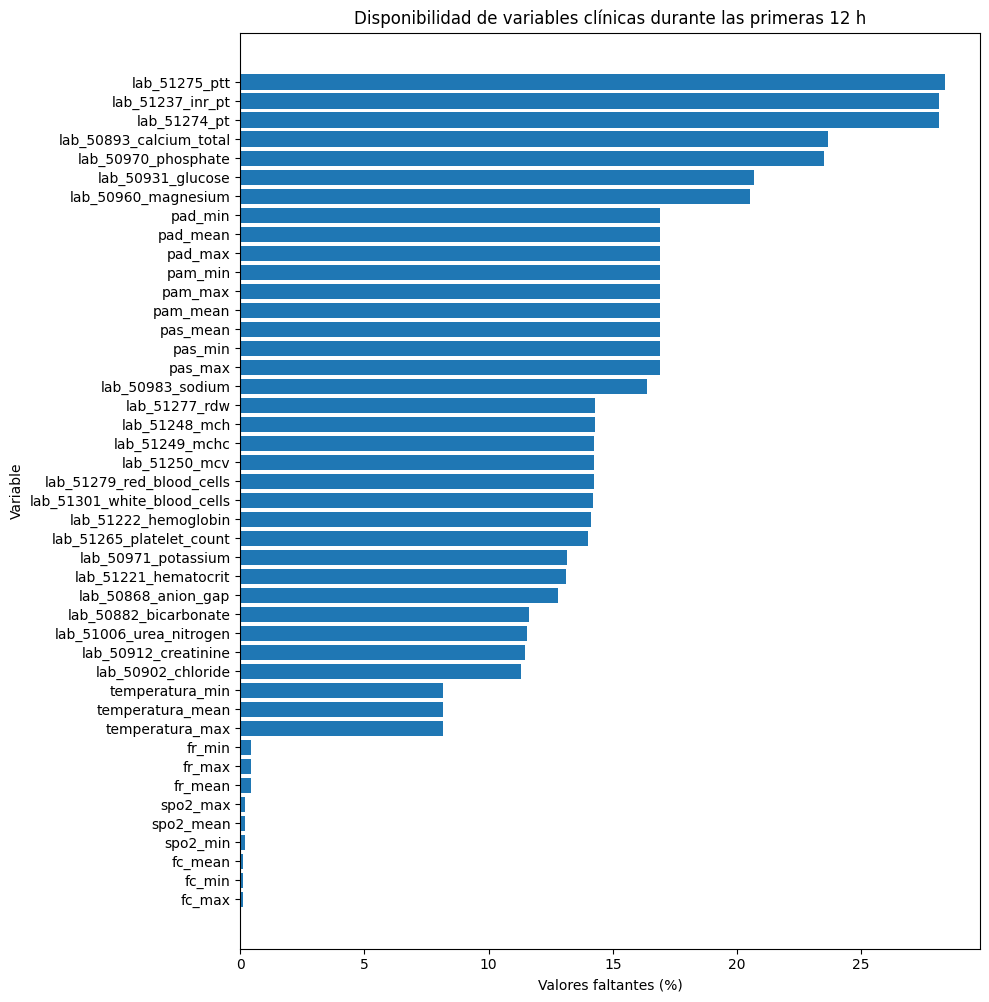

In [5]:
clinicas = [
    c for c in df.columns
    if c.startswith(("fc_", "fr_", "pad_", "pam_", "pas_", "spo2_", "temperatura_", "lab_"))
]

disp_clinicas = resumen[resumen["variable"].isin(clinicas)].copy()

plt.figure(figsize=(10, max(6, len(disp_clinicas) * 0.23)))
plt.barh(
    disp_clinicas.sort_values("pct_faltantes")["variable"],
    disp_clinicas.sort_values("pct_faltantes")["pct_faltantes"]
)
plt.xlabel("Valores faltantes (%)")
plt.ylabel("Variable")
plt.title("Disponibilidad de variables clínicas durante las primeras 12 h")
plt.tight_layout()
plt.show()


## 4. Redundancia entre predictores numéricos

Se utiliza **Spearman** porque no exige relaciones lineales ni normalidad y es apropiada para detectar asociaciones monotónicas fuertes. Se marcan como altamente redundantes los pares con `|ρ| ≥ 0.80`.

El umbral no elimina automáticamente variables: identifica pares que requieren una decisión de representación.


In [6]:
excluir_corr = {
    "subject_id", "hadm_id", "stay_id",
    "los", "los_restante_dias", "los_gt_3d",
    "n_faltantes_clinicos", "pct_faltantes_clinicos"
}

numericas_pred = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in excluir_corr
]

corr_spearman = df[numericas_pred].corr(method="spearman")
upper = corr_spearman.abs().where(
    np.triu(np.ones(corr_spearman.shape), k=1).astype(bool)
)

pares_redundantes = (
    upper.stack()
    .reset_index()
    .rename(columns={
        "level_0": "variable_1",
        "level_1": "variable_2",
        0: "rho_abs"
    })
    .query("rho_abs >= 0.80")
    .sort_values("rho_abs", ascending=False)
    .reset_index(drop=True)
)

display(pares_redundantes)


,variable_1,variable_2,rho_abs
0,lab_51237_inr_pt,lab_51274_pt,0.972894
1,lab_51221_hematocrit,lab_51222_hemoglobin,0.947028
2,pad_mean,pam_mean,0.938442
3,pad_max,pam_max,0.925402
4,pad_min,pam_min,0.913778
5,lab_51221_hematocrit,lab_51279_red_blood_cells,0.904776
6,fc_min,fc_mean,0.904335
7,fc_mean,fc_max,0.901474
8,lab_51222_hemoglobin,lab_51279_red_blood_cells,0.898819
9,temperatura_mean,temperatura_max,0.883277


## 5. Selección de representación de signos vitales

El dataset contiene mínimo, media y máximo de cada signo durante las primeras 12 horas. Mantener las tres medidas incrementa dimensionalidad y puede introducir redundancia.

Para un **modelo mínimo**, se selecciona una sola representación por signo vital. Se utiliza la **media de 12 h** como resumen de la exposición habitual durante la ventana, mientras que mínimos y máximos quedan disponibles en el dataset maestro para análisis de sensibilidad posteriores.

Para presión arterial se evita conservar simultáneamente PAS, PAD y PAM en el conjunto mínimo. Se conserva inicialmente **PAS media**, una medición directamente registrada y ampliamente interpretable. Más adelante puede compararse contra PAM dentro del conjunto de entrenamiento.


In [7]:
grupos_vitales = {
    "Frecuencia cardiaca": ["fc_min", "fc_mean", "fc_max"],
    "Frecuencia respiratoria": ["fr_min", "fr_mean", "fr_max"],
    "SpO2": ["spo2_min", "spo2_mean", "spo2_max"],
    "Temperatura": ["temperatura_min", "temperatura_mean", "temperatura_max"],
    "PAS": ["pas_min", "pas_mean", "pas_max"],
    "PAD": ["pad_min", "pad_mean", "pad_max"],
    "PAM": ["pam_min", "pam_mean", "pam_max"],
}

filas = []
for grupo, cols in grupos_vitales.items():
    cols = [c for c in cols if c in df.columns]
    for c in cols:
        otras = [x for x in cols if x != c]
        max_corr = (
            df[[c] + otras].corr(method="spearman")[c]
            .drop(c, errors="ignore").abs().max()
            if otras else np.nan
        )
        filas.append({
            "signo": grupo,
            "variable": c,
            "pct_faltantes": df[c].isna().mean() * 100,
            "rho_spearman_target": df[[c, "los_restante_dias"]]
                .corr(method="spearman").iloc[0, 1],
            "max_rho_dentro_del_signo": max_corr
        })

comparacion_vitales = pd.DataFrame(filas)
display(comparacion_vitales)


,signo,variable,pct_faltantes,rho_spearman_target,max_rho_dentro_del_signo
0,Frecuencia cardiaca,fc_min,0.122697,0.085928,0.904335
1,Frecuencia cardiaca,fc_mean,0.122697,0.099722,0.904335
2,Frecuencia cardiaca,fc_max,0.122697,0.102256,0.901474
3,Frecuencia respiratoria,fr_min,0.429991,0.090748,0.716839
4,Frecuencia respiratoria,fr_mean,0.429991,0.128098,0.771605
5,Frecuencia respiratoria,fr_max,0.429991,0.089140,0.771605
6,SpO2,spo2_min,0.195651,-0.001652,0.801415
7,SpO2,spo2_mean,0.195651,0.061143,0.801415
8,SpO2,spo2_max,0.195651,0.068525,0.695187
9,Temperatura,temperatura_min,8.165408,0.054684,0.848706


In [8]:
vitales_seleccionados = [
    c for c in [
        "fc_mean",
        "fr_mean",
        "spo2_mean",
        "temperatura_mean",
        "pas_mean"
    ]
    if c in df.columns
]

print("Signos vitales seleccionados:")
print(vitales_seleccionados)


Signos vitales seleccionados:
['fc_mean', 'fr_mean', 'spo2_mean', 'temperatura_mean', 'pas_mean']


## 6. Selección de laboratorios

Para favorecer generalización y parsimonia se propone un **panel básico**:

- bicarbonato, cloro, creatinina, glucosa, potasio, sodio y nitrógeno ureico;
- hemoglobina, plaquetas y leucocitos.

Se evita conservar simultáneamente múltiples índices que representan componentes muy próximos del hemograma (`hematocrit`, `hemoglobin`, `red_blood_cells`, `MCH`, `MCHC`, `MCV`, `RDW`). Para el modelo mínimo se conserva **hemoglobina** como representación de la serie roja.

Asimismo, `PT`, `INR` y `PTT` presentan mayor ausencia que gran parte del panel básico y corresponden a evaluación de coagulación; no se incluyen en el conjunto mínimo. El dataset maestro permanece intacto, por lo que estas variables pueden evaluarse posteriormente en análisis de sensibilidad.


In [9]:
labs_seleccionados = [
    c for c in [
        "lab_50882_bicarbonate",
        "lab_50902_chloride",
        "lab_50912_creatinine",
        "lab_50931_glucose",
        "lab_50971_potassium",
        "lab_50983_sodium",
        "lab_51006_urea_nitrogen",
        "lab_51222_hemoglobin",
        "lab_51265_platelet_count",
        "lab_51301_white_blood_cells"
    ]
    if c in df.columns
]

tabla_labs = pd.DataFrame({
    "variable": labs_seleccionados,
    "pct_faltantes": [df[c].isna().mean() * 100 for c in labs_seleccionados],
    "rho_spearman_target": [
        df[[c, "los_restante_dias"]].corr(method="spearman").iloc[0, 1]
        for c in labs_seleccionados
    ]
})

display(tabla_labs.sort_values("pct_faltantes"))


,variable,pct_faltantes,rho_spearman_target
1,lab_50902_chloride,11.296937,-0.028332
2,lab_50912_creatinine,11.484851,0.100379
6,lab_51006_urea_nitrogen,11.541225,0.132383
0,lab_50882_bicarbonate,11.642920,-0.074673
4,lab_50971_potassium,13.156178,0.019246
8,lab_51265_platelet_count,14.015055,-0.014408
7,lab_51222_hemoglobin,14.135541,-0.068147
9,lab_51301_white_blood_cells,14.206285,0.123540
5,lab_50983_sodium,16.387191,0.006226
3,lab_50931_glucose,20.701471,0.108151


## 7. Variables demográficas

Se conservan `edad_ingreso` y `gender`. Son características basales disponibles al ingreso y no dependen de resultados posteriores a las 12 horas.


In [10]:
demograficas = [c for c in ["edad_ingreso", "gender"] if c in df.columns]
print(demograficas)


['edad_ingreso', 'gender']


## 8. Tabla formal de justificación

La siguiente tabla documenta la decisión final. Esta tabla puede utilizarse como evidencia metodológica en el reporte.


In [11]:
seleccionadas = demograficas + vitales_seleccionados + labs_seleccionados

def categoria_variable(c):
    if c in demograficas:
        return "Demográfica"
    if c in vitales_seleccionados:
        return "Signo vital"
    if c in labs_seleccionados:
        return "Laboratorio"
    return "Otra"

def justificacion(c):
    if c == "edad_ingreso":
        return "Característica basal disponible al ingreso; se conserva para ajuste demográfico."
    if c == "gender":
        return "Característica basal disponible al ingreso; se conserva para ajuste demográfico."
    if c in vitales_seleccionados:
        return "Signo vital de monitorización general; se conserva una representación media de 0–<12 h para reducir redundancia min/media/max."
    if c == "lab_51222_hemoglobin":
        return "Laboratorio básico; representa la serie roja evitando conservar simultáneamente hematocrito, eritrocitos e índices eritrocitarios altamente relacionados."
    if c in ["lab_51265_platelet_count", "lab_51301_white_blood_cells"]:
        return "Componente básico del hemograma; se conserva como predictor clínico general."
    if c in labs_seleccionados:
        return "Prueba bioquímica básica; se prioriza por generalidad clínica y disponibilidad en la cohorte."
    return ""

tabla_seleccion = pd.DataFrame({
    "variable": seleccionadas,
    "categoria": [categoria_variable(c) for c in seleccionadas],
    "pct_faltantes": [
        df[c].isna().mean() * 100 if c in df.columns else np.nan
        for c in seleccionadas
    ],
    "justificacion": [justificacion(c) for c in seleccionadas]
})

display(tabla_seleccion)
print(f"Predictoras seleccionadas: {len(seleccionadas)}")


,variable,categoria,pct_faltantes,justificacion
0,edad_ingreso,Demográfica,0.000000,Característica basal disponible al ingreso; se...
1,gender,Demográfica,0.000000,Característica basal disponible al ingreso; se...
2,fc_mean,Signo vital,0.122697,Signo vital de monitorización general; se cons...
3,fr_mean,Signo vital,0.429991,Signo vital de monitorización general; se cons...
4,spo2_mean,Signo vital,0.195651,Signo vital de monitorización general; se cons...
5,temperatura_mean,Signo vital,8.165408,Signo vital de monitorización general; se cons...
6,pas_mean,Signo vital,16.892347,Signo vital de monitorización general; se cons...
7,lab_50882_bicarbonate,Laboratorio,11.642920,Prueba bioquímica básica; se prioriza por gene...
8,lab_50902_chloride,Laboratorio,11.296937,Prueba bioquímica básica; se prioriza por gene...
9,lab_50912_creatinine,Laboratorio,11.484851,Prueba bioquímica básica; se prioriza por gene...


Predictoras seleccionadas: 17


## 9. Comprobación de redundancia del conjunto reducido

Después de la selección conceptual se vuelve a calcular la correlación entre las variables numéricas conservadas. Esto permite comprobar si todavía existen pares con `|ρ| ≥ 0.80`.

Si aparecen pares altamente correlacionados, **no se eliminan silenciosamente**: deben revisarse antes del modelado y documentarse.


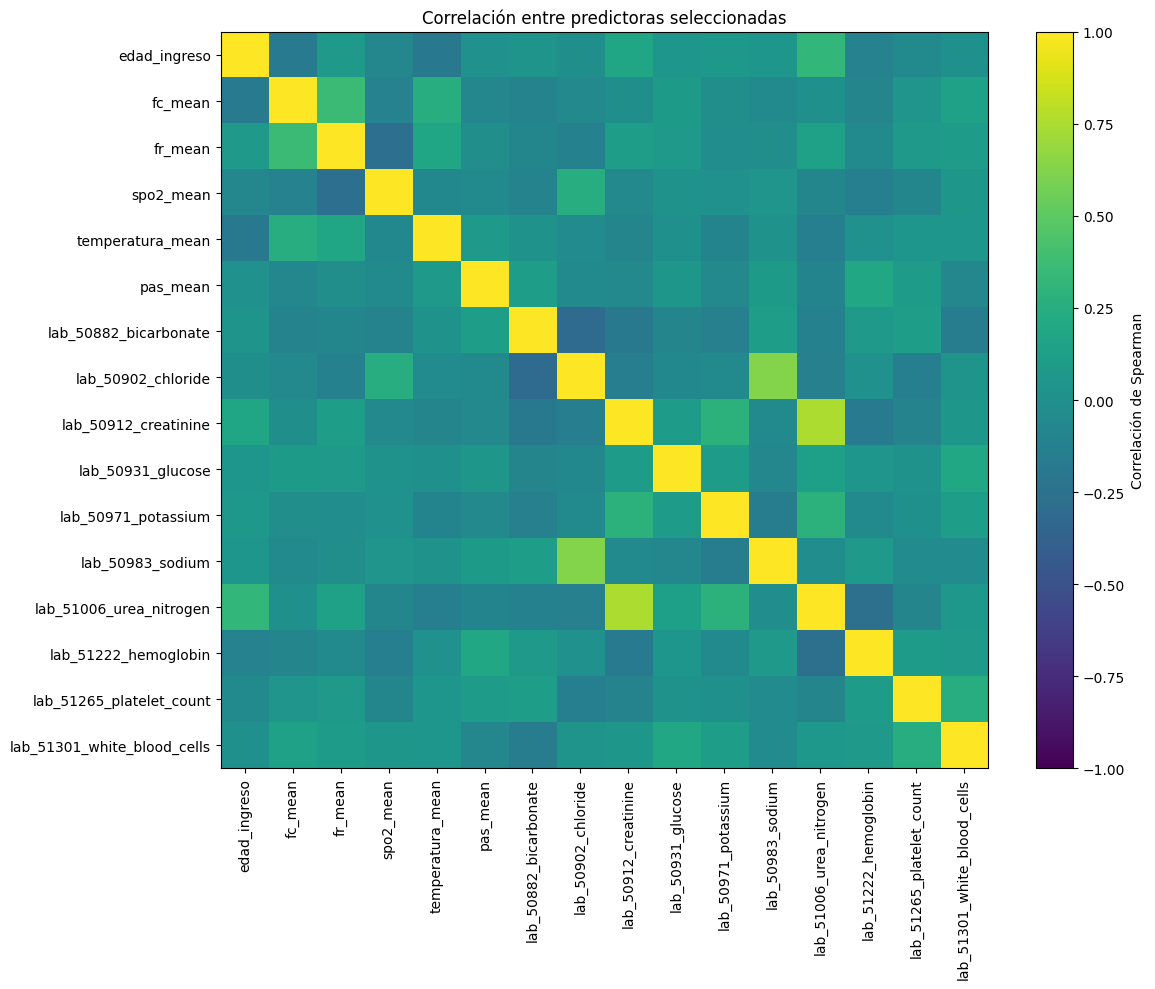

Pares con |rho| >= 0.80 después de la selección:


,variable_1,variable_2,rho_abs


In [12]:
num_finales = [
    c for c in seleccionadas
    if c in df.select_dtypes(include=np.number).columns
]

corr_final = df[num_finales].corr(method="spearman")

plt.figure(figsize=(12, 10))
plt.imshow(corr_final, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlación de Spearman")
plt.xticks(range(len(corr_final.columns)), corr_final.columns, rotation=90)
plt.yticks(range(len(corr_final.columns)), corr_final.columns)
plt.title("Correlación entre predictoras seleccionadas")
plt.tight_layout()
plt.show()

upper_final = corr_final.abs().where(
    np.triu(np.ones(corr_final.shape), k=1).astype(bool)
)

pares_finales_altos = (
    upper_final.stack()
    .reset_index()
    .rename(columns={"level_0":"variable_1", "level_1":"variable_2", 0:"rho_abs"})
    .query("rho_abs >= 0.80")
    .sort_values("rho_abs", ascending=False)
)

print("Pares con |rho| >= 0.80 después de la selección:")
display(pares_finales_altos)


## 10. Construcción del dataset final reducido

El archivo final conserva:

- `subject_id`: para partición por paciente y trazabilidad;
- `stay_id`: identificador de la estancia;
- predictores seleccionados;
- `los_restante_dias`: target.

Los identificadores **no deben incluirse en la matriz de predictores `X`**.

El dataset maestro de 54 variables no se modifica ni se reemplaza.


In [13]:
ids_finales = [c for c in ["subject_id", "stay_id"] if c in df.columns]
target = ["los_restante_dias"]

columnas_finales = ids_finales + seleccionadas + target
dataset_final = df[columnas_finales].copy()

print(f"Dataset maestro: {df.shape[0]:,} × {df.shape[1]}")
print(f"Dataset final reducido: {dataset_final.shape[0]:,} × {dataset_final.shape[1]}")
print("\nColumnas:")
print(dataset_final.columns.tolist())

display(dataset_final.head())


Dataset maestro: 90,467 × 54
Dataset final reducido: 90,467 × 20

Columnas:
['subject_id', 'stay_id', 'edad_ingreso', 'gender', 'fc_mean', 'fr_mean', 'spo2_mean', 'temperatura_mean', 'pas_mean', 'lab_50882_bicarbonate', 'lab_50902_chloride', 'lab_50912_creatinine', 'lab_50931_glucose', 'lab_50971_potassium', 'lab_50983_sodium', 'lab_51006_urea_nitrogen', 'lab_51222_hemoglobin', 'lab_51265_platelet_count', 'lab_51301_white_blood_cells', 'los_restante_dias']


,subject_id,stay_id,edad_ingreso,gender,fc_mean,fr_mean,spo2_mean,temperatura_mean,pas_mean,lab_50882_bicarbonate,lab_50902_chloride,lab_50912_creatinine,lab_50931_glucose,lab_50971_potassium,lab_50983_sodium,lab_51006_urea_nitrogen,lab_51222_hemoglobin,lab_51265_platelet_count,lab_51301_white_blood_cells,los_restante_dias
0,10000690,37081114,86,F,77.769231,22.615385,96.615385,97.600000,110.833333,26.0,104.0,0.9,77.0,4.4,137.0,21.0,9.5,199.0,7.5,3.393252
1,10001217,37067082,55,F,91.153846,22.076923,97.307692,98.850000,137.692308,23.0,104.0,0.4,113.0,3.6,138.0,9.0,11.2,285.0,19.0,0.618032
2,10001217,34592300,55,F,80.142857,15.357143,94.071429,97.866667,122.384615,24.0,106.0,0.5,113.0,4.3,139.0,10.0,12.3,299.0,8.4,0.448113
3,10001725,31205490,46,F,79.307692,17.461538,97.833333,97.700000,96.230769,24.0,102.0,0.8,152.0,3.5,138.0,18.0,12.6,299.0,20.1,0.838588
4,10001843,39698942,76,M,122.307692,21.153846,95.538462,97.666667,93.692308,20.0,101.0,1.7,108.0,5.4,137.0,33.0,9.1,609.0,10.5,0.325266


In [14]:
print("Faltantes del dataset final:")
display(
    (dataset_final.isna().mean() * 100)
    .sort_values(ascending=False)
    .to_frame("pct_faltantes")
)

print("\nTarget faltante:", dataset_final["los_restante_dias"].isna().sum())
print("stay_id duplicados:", dataset_final["stay_id"].duplicated().sum())


Faltantes del dataset final:


,pct_faltantes
lab_50931_glucose,20.701471
pas_mean,16.892347
lab_50983_sodium,16.387191
lab_51301_white_blood_cells,14.206285
lab_51222_hemoglobin,14.135541
lab_51265_platelet_count,14.015055
lab_50971_potassium,13.156178
lab_50882_bicarbonate,11.642920
lab_51006_urea_nitrogen,11.541225
lab_50912_creatinine,11.484851



Target faltante: 0
stay_id duplicados: 0


## 11. Guardar resultados

Se guardan dos archivos:

1. el dataset reducido para el siguiente notebook de modelado;
2. una tabla de justificación de las variables seleccionadas.

La imputación de faltantes **no se realiza aquí** para evitar fuga de información. Se ajustará posteriormente utilizando únicamente el conjunto de entrenamiento.


In [15]:
OUTPUT_DIR = INTERIM_DIR
RESULTS_SELECTION_DIR = RESULTS_DIR / "seleccion_variables"
RESULTS_SELECTION_DIR.mkdir(parents=True, exist_ok=True)

ruta_dataset = OUTPUT_DIR / "mimic_uci_12h_regresion_final.csv.gz"
ruta_justificacion = RESULTS_SELECTION_DIR / "justificacion_variables_regresion.csv"

dataset_final.to_csv(
    ruta_dataset,
    index=False,
    compression="gzip"
)

tabla_seleccion.to_csv(
    ruta_justificacion,
    index=False
)

print("Dataset final guardado en:", ruta_dataset)
print("Justificación guardada en:", ruta_justificacion)


Dataset final guardado en: C:\Users\grise\Downloads\estancia-hospitalaria-uci\data\interim\mimic_uci_12h_regresion_final.csv.gz
Justificación guardada en: C:\Users\grise\Downloads\estancia-hospitalaria-uci\results\seleccion_variables\justificacion_variables_regresion.csv


## Conclusión metodológica

La reducción del conjunto de predictores no se basa únicamente en su asociación con el target. Se busca un compromiso entre **disponibilidad, interpretabilidad, generalización y baja redundancia**. El dataset completo permanece como fuente maestra, mientras que el conjunto reducido constituye la especificación inicial para los modelos de regresión.

En el siguiente notebook debe realizarse la separación train/test **por `subject_id`**, seguida de imputación, codificación y diagnóstico de multicolinealidad utilizando exclusivamente la información del conjunto de entrenamiento.
